# Parallel execution and memory

This example prepares DuckDB inputs from Pandas, fits the same AdaSTEM with native queries and shared numeric arrays, and checks predictions. It uses bundled bird observations and three ensembles so it can run offline on a laptop. The random held-out split checks execution equivalence; it is not a spatial validation or calibration experiment.

The benchmark section compares complete jobs on identical inputs. Peak memory includes training and prediction. Keep DuckDB as the default and test shared arrays on the machine where the full workflow will run.


In [1]:
from pathlib import Path
import gc
import json
import pickle
import platform
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.tree import DecisionTreeClassifier

from stemflow.lazyloading import make_training_databases, make_duckdb_database
from stemflow.model.AdaSTEM import AdaSTEMClassifier

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "docs/mini_data/mini_data.pkl").exists())
print(platform.platform())
with (ROOT / "docs/mini_data/mini_data.pkl").open("rb") as handle:
    observations = pickle.load(handle).sample(8000, random_state=42)
features = ["longitude", "latitude", "DOY", "duration_minutes",
            "time_observation_started_minute_of_day", "elevation_mean", "bio1"]
X = observations[features].fillna(-1).copy()
y = (observations["count"] > 0).astype("int8").rename("occurrence")
del observations
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training rows: {len(X_train):,}; held-out rows: {len(X_test):,}")
print(f"Training detections: {int(y_train.sum()):,}")


macOS-15.7.7-arm64-arm-64bit-Mach-O
Training rows: 6,400; held-out rows: 1,600
Training detections: 784


## Prepare inputs and compare execution

The helpers supply observation IDs and align the target to those IDs. Temporary files live in one context and are removed after both fits and predictions. Lazy models use separate folders. This example retains the small source frames for demonstration; release unneeded frames after database creation in a large workflow.

Both fits use temporal-window prequerying, two workers, the same grids and estimator settings. The shared backend changes data access, not the base estimator or probability calibration. Recorded fit time includes partitioning and shared-file preparation.


In [2]:
results, predictions = [], {}
with tempfile.TemporaryDirectory(prefix="stemflow_example_") as scratch:
    X_path, y_path = make_training_databases(X_train, y_train, Path(scratch) / "training")
    test_path = make_duckdb_database(X_test, Path(scratch) / "test.duckdb")
    for backend in ["native", "memmap"]:
        model = AdaSTEMClassifier(
            base_model=DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42),
            ensemble_fold=3, min_ensemble_required=2,
            grid_len_upper_threshold=40, grid_len_lower_threshold=5,
            points_lower_threshold=100,
            temporal_start=1, temporal_end=366, temporal_step=60, temporal_bin_interval=80,
            n_jobs=2, random_state=42, sample_weights_for_classifier=False,
            lazy_loading=True, lazy_loading_dir=str(Path(scratch) / backend),
            save_gridding_plot=False, verbosity=0,
        )
        started = time.perf_counter()
        model.fit(X_path, y_path, training_data_backend=backend,
                  temporal_window_prequery=True, inner_max_num_threads=1,
                  max_concurrent_ensembles=2)
        fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        p = model.predict_proba(test_path, temporal_window_prequery=True, n_jobs=2)[:, 1]
        prediction_seconds = time.perf_counter() - started
        predictions[backend] = p
        valid = np.isfinite(p)
        results.append(dict(backend=backend, fit_seconds=fit_seconds,
            prediction_seconds=prediction_seconds, coverage=valid.mean(),
            AUC=roc_auc_score(y_test.to_numpy()[valid], p[valid]),
            Brier=brier_score_loss(y_test.to_numpy()[valid], p[valid]),
            shared_file_MiB=model.execution_info_["shared_input_bytes"] / 1024**2))
        del model
        gc.collect()

table = pd.DataFrame(results).set_index("backend")
display(table.round(5))
np.testing.assert_allclose(predictions["native"], predictions["memmap"], atol=0, rtol=0, equal_nan=True)
print("Predictions and missing-coverage positions match exactly.")


Predictions and missing-coverage positions match exactly.


/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/model/AdaSTEM.py:1119: UserWarning: There are 0.07125% points (114 points) falling out of predictable range.
  warnings.warn(f"There are {nan_frac}% points ({nan_count} points) falling out of predictable range.")
/Users/chenyangkang/Desktop/optimize_adastem/stemflow/stemflow/model/AdaSTEM.py:1119: UserWarning: There are 0.07125% points (114 points) falling out of predictable range.
  warnings.warn(f"There are {nan_frac}% points ({nan_count} points) falling out of predictable range.")


,fit_seconds,prediction_seconds,coverage,AUC,Brier,shared_file_MiB
backend,,,,,,
native,2.55035,1.63066,0.92875,0.67595,0.10761,0.00000
memmap,2.51146,1.61810,0.92875,0.67595,0.10761,0.22656


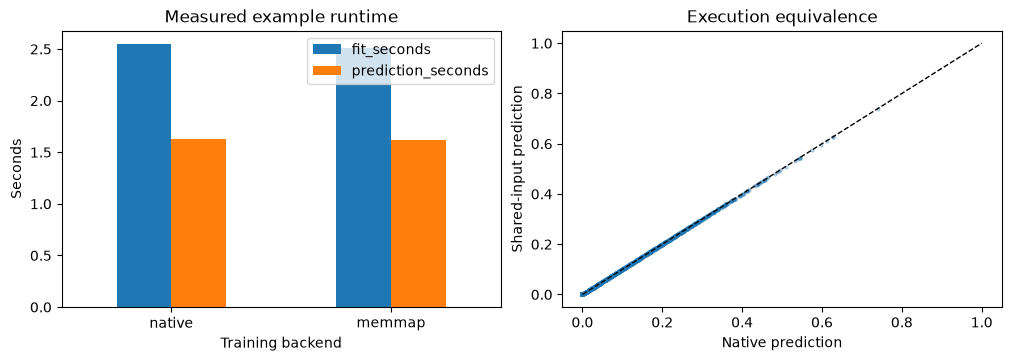

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
table[["fit_seconds", "prediction_seconds"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("Seconds")
axes[0].set_xlabel("Training backend")
axes[0].set_title("Measured example runtime")
a, b = predictions["native"], predictions["memmap"]
valid = np.isfinite(a) & np.isfinite(b)
axes[1].scatter(a[valid], b[valid], s=5, alpha=0.25)
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set(xlabel="Native prediction", ylabel="Shared-input prediction", title="Execution equivalence")
plt.show()


## Complete job benchmarks

The saved comparisons use isolated baseline and rewrite processes, one run per variant and fixture. They include imports, database creation, partitioning, fitting, held-out prediction, metric calculation and full prediction. Each variant receives the same data and model settings. Full source databases are read-only; temporary files are cleaned up.

The eight cases vary real and synthetic data, rows, predictors, ensembles, workers, and resident versus lazy Random Forest models. These results were measured on Apple Silicon. macOS physical footprint, summed RSS, Linux PSS and Slurm cgroup memory have different meanings; an HPC memory request needs a run on that system. Shared arrays can reduce footprint while increasing summed RSS because mappings appear in several processes.


,case,variant,wall_seconds,fit_seconds,prediction_seconds,peak_accounted_mb,peak_rss_mb,saved_models_mb,shared_file_mb
0,acadian_100000_e4,baseline,16.36,2.48,1.69,1351.17,2648.30,1.87,0.00
1,acadian_100000_e4,rewrite_native,16.20,2.43,1.66,1310.39,2516.28,1.87,0.00
2,acadian_100000_e4,rewrite_memmap,16.34,2.65,1.62,1162.88,2434.98,1.87,36.35
3,acadian_100000_e8,baseline,18.11,3.56,2.02,1363.19,3053.41,3.87,0.00
4,acadian_100000_e8,rewrite_native,17.88,3.51,1.90,1314.88,2945.16,3.87,0.00
5,acadian_100000_e8,rewrite_memmap,17.81,3.65,1.91,1156.42,2814.92,3.87,36.35
6,acadian_100000_e8_j2,baseline,21.10,5.53,2.37,864.89,2082.23,3.87,0.00
7,acadian_100000_e8_j2,rewrite_native,20.53,5.33,2.43,814.14,2007.69,3.87,0.00
8,acadian_100000_e8_j2,rewrite_memmap,20.29,5.47,2.14,712.46,1787.77,3.87,36.35
9,acadian_30000_e4,baseline,15.26,2.26,1.66,720.84,1275.81,1.44,0.00


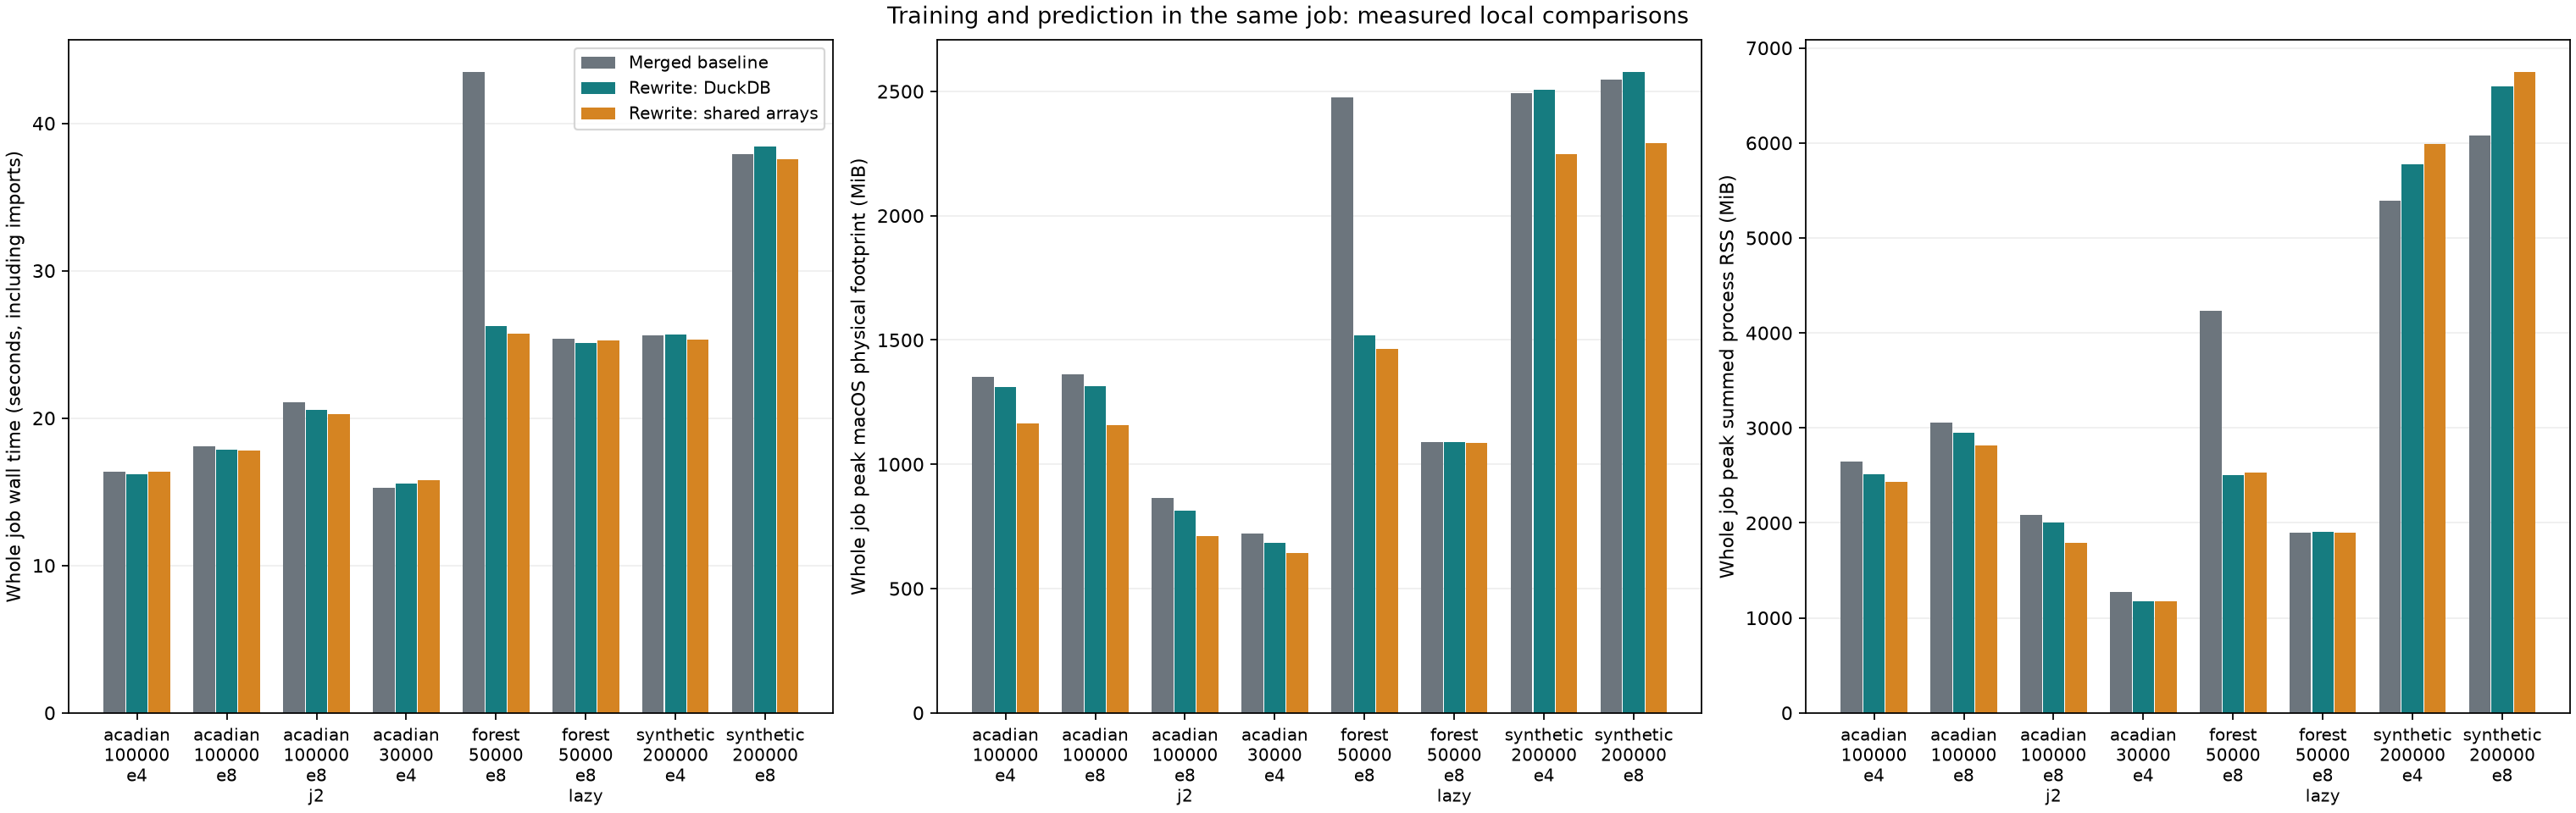

In [4]:
summary_path = ROOT / "data/00_benchmarks/summary.json"
if summary_path.exists():
    benchmark = pd.DataFrame(json.loads(summary_path.read_text()))
    selected = ["case", "variant", "wall_seconds", "fit_seconds", "prediction_seconds",
                "peak_accounted_mb", "peak_rss_mb", "saved_models_mb", "shared_file_mb"]
    display(benchmark[selected].round(2))
    assert benchmark.same_nan_mask.all() and benchmark.same_full_nan_mask.all()
    assert benchmark.max_prediction_difference.max() == 0
    assert benchmark.max_full_prediction_difference.max() == 0
    display(Image(filename=str(ROOT / "figures/00_benchmarks/whole_job_comparison.png")))
else:
    print("Run scripts/00_benchmarks/run_matrix.py and summarize_results.py for benchmark results.")


## Apply the controls to a larger job

Use `ensemble_fold` for the desired number of ensembles and choose `n_jobs` for the available CPU and memory budget. The `fit` argument `max_concurrent_ensembles` caps partitioning and training concurrency. Set prediction's `n_jobs` separately. Set each base estimator's own thread count explicitly; `inner_max_num_threads` applies to supported native libraries in loky training workers.

`max_mem` controls DuckDB's buffer budget, not total process memory. Sharing inputs cannot bound an estimator's own workspaces or GPU memory. The shared backend currently supports built-in planar AdaSTEM/STEM training; use native execution for SphereAdaSTEM or custom ensemble-training overrides.

The original example notebooks remain unchanged. This offline example supplements them; their external Mallard and prediction datasets are still needed to rerun them. See [parallel execution and memory](../Tips/Tips_for_parallel_execution.md) for persistent inputs, scratch placement, Linux/HPC measurement and GPU considerations.
